Spc   "L7E-222_CorrRaccHver"'s Poly Loop is missing!
   FLOOR [(204.531, 214.115), (204.531, 205.177), (212.198, 205.177), (212.198, 195.25), (220.229, 195.25), (220.229, 46.1146), (229.698, 46.1146), (229.698, 36.2708), (227.833, 36.2708), (227.833, 23.7396), (214.333, 23.7396), (214.333, 189.333), (146.808, 189.333), (143.695, 167.188), (142.004, 167.426), (122.573, 29.1673), (117.209, 29.9211), (118.483, 38.9883), (109.932, 40.1901), (109.606, 37.8691), (99.7234, 39.258), (100.05, 41.5789), (85.4329, 43.6332), (86.3535, 50.1835), (118.826, 45.6198), (137.069, 175.427), (138.74, 175.193), (142.687, 203.271), (150.719, 203.271), (150.719, 195.25), (199.333, 195.25), (199.333, 214.115), (204.531, 214.115)]
   FLOOR [(117.209, 29.9211), (122.573, 29.1673), (122.403, 27.9604), (117.039, 28.7142), (117.209, 29.9211)]
   FLOOR [(85.4329, 43.6332), (91.3541, 42.901), (89.9101, 32.527), (83.9889, 33.3591), (85.4329, 43.6332)]
   SPACE (122.573, 29.1673)
(122.403, 27.9604)
(117.039, 28.7142)


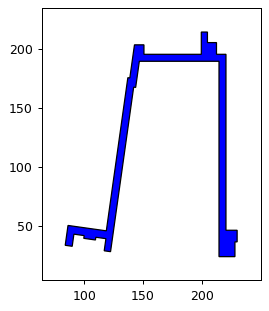

Press Enter to continue... 


Spc   "L7E-276_TrshRaccIncd"'s Poly Loop is missing!
   FLOOR [(199.333, 221.417), (199.333, 214.115), (189.0, 214.115), (189.0, 221.417), (199.333, 221.417)]
   FLOOR [(204.531, 219.063), (204.531, 214.115), (199.333, 214.115), (199.333, 219.063), (204.531, 219.063)]
   FLOOR [(204.531, 221.417), (204.531, 219.063), (199.333, 219.063), (199.333, 221.417), (204.531, 221.417)]
   SPACE (204.531, 219.063)
(204.531, 214.115)
(189.0, 214.115)
(189.0, 221.417)
(204.531, 221.417)
      Z Coordinate  = 68.5
      Number Vertex = 6
      Area          = 113.40736199999992


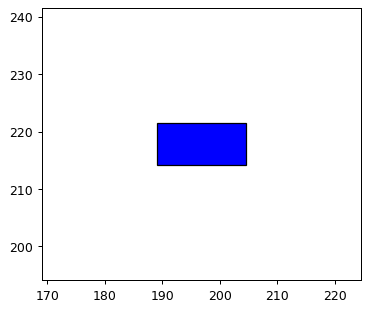

Press Enter to continue... 


   SPACE 

AttributeError: 'GeometryCollection' object has no attribute 'exterior'

In [49]:
import re
from shapely.geometry import Point, Polygon, MultiPolygon
from shapely.ops import cascaded_union
import matplotlib.pyplot as plt
from descartes import PolygonPatch
class color:
   PURPLE = '\033[95m'
   CYAN = '\033[96m'
   DARKCYAN = '\033[36m'
   BLUE = '\033[94m'
   GREEN = '\033[92m'
   YELLOW = '\033[93m'
   RED = '\033[91m'
   BOLD = '\033[1m'
   UNDERLINE = '\033[4m'
   END = '\033[0m'

with open('2044_MDL02.cibd', 'r') as f:
    # f_contents = f.read(200) # read first # of data
    # print(f_contents, end='')
    f_line = f.readline() # read line
    
    IsSpace = False
    IsSpcPolyLp = False
    MissPolyLp = False
    IsFlr = False
    LineCnt = 0
    SpcMissPolyLp = ""
    offset = 4
    LineNmb = 1
    pt = Point(0, 0)
    corrZ = 0
    pts = []
    polyA = Polygon()
    NumbPt = 1
    NumbPoly = 0
    tol = 0.5 # tolerance for polygon simplification
    
    while len(f_line) > 0: # read through each line in cibd file
        LineNmb += 1
        f_line = f.readline()
        
        # Looking for spaces which poly loops are missing!
        if f_line.startswith('Spc   '):
            # print(f_line, end = '')
            IsSpace = True
            SpcMissPolyLp = f_line
        if f_line.startswith('PolyLp   ') and IsSpace == True:
            IsSpcPolyLp = True
        if IsSpcPolyLp == True:
            LineCnt += 1
        if LineCnt == offset and f_line.startswith('CartesianPt   '):
            IsSpace = False
            IsSpcPolyLp = False
            LineCnt = 0
            MissPolyLp = False
        elif LineCnt == offset:
            IsSpace = False
            IsSpcPolyLp = False
            MissPolyLp = True
            LineCnt = 0
            print(color.BOLD + color.RED + SpcMissPolyLp.rstrip() + '\'s Poly Loop is missing!\n' + color.END, end = '')
            
        # Looking for floors. If the previous object is a floor, record the polyloop of the previous floor.
        if MissPolyLp == True and (f_line.startswith('IntFlr   ') or f_line.startswith('ExtFlr   ')  or f_line.startswith('UndgrFlr   ')):
            if IsFlr == True:        
                NumbPoly += 1
                polyB = polyA
                coords = [(p.x, p.y) for p in pts]
                polyA = Polygon(coords)
                print('   FLOOR ', end="")
                print(list(polyA.exterior.coords))
                NumbPt = 1
                if NumbPoly == 2:
                    polys = [polyB, polyA] 
                elif NumbPoly > 2:
                    polys.append(polyA)
            else:
                IsFlr = True
        
        # If the previous object is a floor, record the polyloop of the previous floor.
        elif f_line.startswith('IntWall   ') or f_line.startswith('ExtWall   ') or f_line.startswith('Roof   ') or f_line.startswith('UndgrWall   ') or \
            f_line.startswith('Win   ') or f_line.startswith('Dr   ') or f_line.startswith('Spc   ') or f_line.startswith('Story   ') or f_line.startswith('ThrmlZn   '):
            if IsFlr == True:
                NumbPoly += 1
                polyB = polyA
                coords = [(p.x, p.y) for p in pts]
                polyA = Polygon(coords)
                print('   FLOOR ', end="")
                print(list(polyA.exterior.coords))
                NumbPt = 1
                if NumbPoly == 2:
                    polys = [polyB, polyA]
                elif NumbPoly > 2:
                    polys.append(polyA)
            IsFlr = False
        
        # In the end of the space, merge all the floor polyloops.
        if MissPolyLp == True and (f_line.startswith('Spc   ') or f_line.startswith('Story   ') or f_line.startswith('ThrmlZn   ')):
            if NumbPoly > 1:
                u = cascaded_union(polys).simplify(tol, preserve_topology=False)
                print(color.BLUE + "   SPACE ", end = "")
                for i in range(0, len(u.exterior.coords)-1):
                    print(u.exterior.coords[i])
                print('      Z Coordinate  = ' + str(corrZ))
                print('      Number Vertex = ' + str(len(list(u.exterior.coords))))
                print('      Area          = ' + str(u.area))
                #if type(u) == shapely.geometry.multipolygon.MultiPolygon:
                #    print(color.RED + "Floor Poly Loops are disconnected")
                fig1 = plt.figure(2, figsize=(5, 4), dpi=90)
                ax1 = fig1.add_subplot(111)
                patch1b = PolygonPatch(u, fc='b', ec='k', alpha=1, zorder=2)
                ax1.add_patch(patch1b)
                xrange = [u.bounds[0] - 20, u.bounds[2] + 20]
                yrange = [u.bounds[1] - 20, u.bounds[3] + 20]
                ax1.set_xlim(*xrange)
                ax1.set_ylim(*yrange)
                ax1.set_aspect(1)
                plt.show()
                input("Press Enter to continue...")
                polys = []
                
            else:
                print("   SPACE ", end = "")
                print(PolyA)
                fig1 = plt.figure(2, figsize=(5, 4), dpi=90)
                ax1 = fig1.add_subplot(111)
                patch1b = PolygonPatch(polyA, fc='b', ec='k', alpha=1, zorder=2)
                ax1.add_patch(patch1b)
                xrange = [u.bounds[0] - 20, u.bounds[2] + 20]
                yrange = [u.bounds[1] - 20, u.bounds[3] + 20]
                ax1.set_xlim(*xrange)
                ax1.set_ylim(*yrange)
                ax1.set_aspect(1)
                plt.show()
                input("Press Enter to continue...")
                polys = []
                
        # Record each floor ppolyloop vertex
        if IsFlr == True and f_line.startswith('   Coord'):
            corr = re.findall( r'[-+]?\d*\.\d+|\d+', f_line)
            pt = Point(float(corr[0]), float(corr[1]))
            corrZ = float(corr[2])
            if NumbPt == 1:
                pts = [pt]
            else:
                pts.append(pt)
            NumbPt += 1        
        
    f.seek(0) # back to beginning 
    


In [47]:
# If Error: 'MultiPolygon' object has no attribute 'exterior' appear 
# run this cell to see where the polygon is detached
# try to attach those polygons by moving the vertex

print('there are ' + str(len(u)) + ' detached polygons')
for i in range(len(u)):
    for j in range(0, len(u[i].exterior.coords) -1):
        print(u[i].exterior.coords[j])
    print('--------------------')

if len(u) > 1:
    fig = plt.figure(1, figsize=(10, 10), dpi=90)
    ax = fig.add_subplot(111)
    polypatch = PolygonPatch(u, fc='b', ec='b', alpha=0.5, zorder=2)
    ax.add_patch(polypatch)
    xrange = [u.bounds[0] - 20, u.bounds[2] + 20]
    yrange = [u.bounds[1] - 20, u.bounds[3] + 20]
    #xrange = [80, 95]
    #yrange = [30, 50]
    ax.set_xlim(*xrange)
    ax.set_ylim(*yrange)
    ax.set_aspect(1)



there are 0 detached polygons
